In [5]:
import pm4py
import pandas as pd

log = pm4py.read_xes("/home/barnap86/github_docker/process-mining-pipeline/data/loan_approval.xes")

# log is a DataFrame now, not a list
print(f"Type: {type(log)}")
print(f"Events (rows): {len(log)}")
print(f"Cases: {log['case:concept:name'].nunique()}")
print(f"Columns: {log.shape[1]}")
print(f"\nFirst 5 rows:")
print(log[['case:concept:name', 'concept:name', 'time:timestamp', 'org:resource']].head())   

parsing log, completed traces :: 100%|█| 5000/5000 [00:01<00:00, 3161.29it/s


Type: <class 'pandas.DataFrame'>
Events (rows): 26583
Cases: 5000
Columns: 4

First 5 rows:
  case:concept:name             concept:name            time:timestamp  \
0        LOAN-04422  Submit Loan Application 2025-01-01 05:42:26+00:00   
1        LOAN-04422       Review Application 2025-01-02 08:27:32+00:00   
2        LOAN-04422             Credit Check 2025-01-05 06:28:34+00:00   
3        LOAN-04422             Approve Loan 2025-01-05 15:34:26+00:00   
4        LOAN-04422           Disburse Funds 2025-01-05 20:15:35+00:00   

    org:resource  
0    system_auto  
1      agent_005  
2      agent_005  
3  supervisor_01  
4    system_auto  


In [6]:
case_id = log['case:concept:name'].iloc[0]
trace = log[log['case:concept:name'] == case_id].sort_values('time:timestamp')
print(f"Case: {case_id}")
print(trace[['concept:name', 'time:timestamp', 'org:resource']].to_string(index=False))   

Case: LOAN-04422
           concept:name            time:timestamp  org:resource
Submit Loan Application 2025-01-01 05:42:26+00:00   system_auto
     Review Application 2025-01-02 08:27:32+00:00     agent_005
           Credit Check 2025-01-05 06:28:34+00:00     agent_005
           Approve Loan 2025-01-05 15:34:26+00:00 supervisor_01
         Disburse Funds 2025-01-05 20:15:35+00:00   system_auto


In [7]:
import pm4py
import matplotlib.pyplot as plt

# Discover process model
process_tree = pm4py.discover_process_tree_inductive(log)
print(f"Process tree: {process_tree}")

# Convert to Petri Net for visualization
net, im, fm = pm4py.convert_to_petri_net(process_tree)

# Save as SVG
pm4py.save_vis_petri_net(net, im, fm, "output/process_model.svg",
    graph_title="Loan Approval - Discovered Process Model")
print("Saved: output/process_model.svg")

# Also save DFG (easier to read)
dfg = pm4py.discover_dfg(log)
pm4py.save_vis_dfg(dfg, "output/dfg.svg",
    graph_title="Loan Approval - Directly-Follows Graph")
print("Saved: output/dfg.svg")   

Process tree: ->( 'Submit Loan Application', +( *( 'Review Application', tau ), X( tau, ->( X( tau, 'Place on Hold' ), +( *( 'Credit Check', tau ), X( tau, ->( 'Reject Loan', X( tau, 'Resubmit Application' ) ) ) ) ) ) ), X( tau, ->( X( tau, ->( 'Escalate', 'Senior Review' ) ), 'Approve Loan', 'Disburse Funds' ) ) )


FileNotFoundError: [Errno 2] No such file or directory: 'output/process_model.svg'

In [8]:
import os
os.makedirs("/home/barnap86/github_docker/process-mining-pipeline/output", exist_ok=True)

pm4py.save_vis_petri_net(net, im, fm,
    "/home/barnap86/github_docker/process-mining-pipeline/output/process_model.svg",
    graph_title="Loan Approval - Discovered Process Model")   

''

In [9]:
pm4py.save_vis_dfg(dfg,
    "/home/barnap86/github_docker/process-mining-pipeline/output/dfg.svg",
    graph_title="Loan Approval - Directly-Follows Graph")   

NameError: name 'dfg' is not defined

In [10]:
dfg = pm4py.discover_dfg(log)
pm4py.save_vis_dfg(dfg,
    "/home/barnap86/github_docker/process-mining-pipeline/output/dfg.svg",
    graph_title="Loan Approval - Directly-Follows Graph")   

TypeError: save_vis_dfg() missing 2 required positional arguments: 'end_activities' and 'file_path'

In [11]:
dfg, start_activities, end_activities = pm4py.discover_dfg(log)

pm4py.save_vis_dfg(dfg, start_activities, end_activities,
    "/home/barnap86/github_docker/process-mining-pipeline/output/dfg.svg")   

''

In [13]:
variants = pm4py.get_variants(log,
    activity_key='concept:name',
    case_id_key='case:concept:name',
    timestamp_key='time:timestamp')

total = log['case:concept:name'].nunique()
print(f"Total unique variants: {len(variants)}")
print(f"\nTop 10 variants:")
for i, (variant, count) in enumerate(sorted(variants.items(), key=lambda x: x[1], reverse=True)[:10]):
    pct = count / total * 100
    print(f"  {i+1}. ({count}, {pct:.1f}%) → {' → '.join(variant)}")   

Total unique variants: 6

Top 10 variants:
  1. (3018, 60.4%) → Submit Loan Application → Review Application → Credit Check → Approve Loan → Disburse Funds
  2. (720, 14.4%) → Submit Loan Application → Review Application → Credit Check → Reject Loan
  3. (509, 10.2%) → Submit Loan Application → Review Application → Credit Check → Reject Loan → Resubmit Application → Review Application → Credit Check → Approve Loan → Disburse Funds
  4. (413, 8.3%) → Submit Loan Application → Review Application → Approve Loan → Disburse Funds
  5. (247, 4.9%) → Submit Loan Application → Review Application → Place on Hold → Review Application → Credit Check → Approve Loan → Disburse Funds
  6. (93, 1.9%) → Submit Loan Application → Review Application → Credit Check → Escalate → Senior Review → Approve Loan → Disburse Funds


In [15]:
# Token-based replay diagnostics (per-trace fit info)
replay_results = pm4py.conformance_diagnostics_token_based_replay(
    log, net, im, fm,
    activity_key='concept:name',
    case_id_key='case:concept:name',
    timestamp_key='time:timestamp'
)

# Overall fitness (one number)
fitness = pm4py.fitness_token_based_replay(
    log, net, im, fm,
    activity_key='concept:name',
    case_id_key='case:concept:name',
    timestamp_key='time:timestamp'
)

print(f"Log fitness: {fitness['log_fitness']:.4f}")
print(f"Average trace fitness: {fitness['average_trace_fitness']:.4f}")
print(f"% fit traces: {fitness['percentage_of_fitting_traces']:.1f}%")

# Worst traces
replay_df = pd.DataFrame(replay_results)
replay_df = replay_df.sort_values('trace_fitness')
print(f"\n5 most deviant cases:")
for _, row in replay_df.head(5).iterrows():
    case_id = row['case:concept:name']
    trace = log[log['case:concept:name'] == case_id].sort_values('time:timestamp')
    path = ' → '.join(trace['concept:name'].tolist())
    print(f"  {case_id} (fitness={row['trace_fitness']:.3f}): {path}")   

replaying log with TBR, completed traces :: 100%|█| 6/6 [00:00<00:00, 76.84i
replaying log with TBR, completed traces :: 100%|█| 6/6 [00:00<00:00, 69.67i


Log fitness: 1.0000
Average trace fitness: 1.0000
% fit traces: 100.0%

5 most deviant cases:


KeyError: 'case:concept:name'

In [16]:
replay_df = pd.DataFrame(replay_results)
print(replay_df.columns.tolist())
print(replay_df.head(2))   

['trace_is_fit', 'trace_fitness', 'activated_transitions', 'reached_marking', 'enabled_transitions_in_marking', 'transitions_with_problems', 'missing_tokens', 'consumed_tokens', 'remaining_tokens', 'produced_tokens']
   trace_is_fit  trace_fitness  \
0          True            1.0   
1          True            1.0   

                               activated_transitions reached_marking  \
0  [(6ea58000-33fb-4c31-bc10-b591e63192bc, 'Submi...       {sink: 1}   
1  [(6ea58000-33fb-4c31-bc10-b591e63192bc, 'Submi...       {sink: 1}   

  enabled_transitions_in_marking transitions_with_problems  missing_tokens  \
0                             {}                        []               0   
1                             {}                        []               0   

   consumed_tokens  remaining_tokens  produced_tokens  
0               14                 0               14  
1               14                 0               14  


In [17]:
from pm4py.algo.performance import algorithm as perf_algo
import matplotlib.pyplot as plt

performance = perf_algo.get_activity_performance(log)
perf_df = pd.DataFrame(performance, columns=["activity", "mean_duration"])
perf_df["mean_duration_hours"] = perf_df["mean_duration"] / 3600
perf_df = perf_df.sort_values("mean_duration_hours", ascending=False)

print("Mean time per activity:")
print(perf_df.to_string(index=False))

plt.figure(figsize=(10, 5))
perf_df.set_index("activity")["mean_duration_hours"].plot(kind="barh")
plt.xlabel("Mean duration (hours)")
plt.title("Throughput Time by Activity")
plt.tight_layout()
plt.savefig("/home/barnap86/github_docker/process-mining-pipeline/output/performance.svg", bbox_inches="tight")
plt.show()   

ModuleNotFoundError: No module named 'pm4py.algo.performance'

In [18]:
import matplotlib.pyplot as plt

# Performance DFG: edges annotated with mean elapsed time between activities
perf_dfg, start_acts, end_acts = pm4py.discover_performance_dfg(
    log,
    case_id_key='case:concept:name',
    activity_key='concept:name',
    timestamp_key='time:timestamp'
)

# Save the visualization (edges show mean time between activities)
pm4py.save_vis_performance_dfg(
    perf_dfg, start_acts, end_acts,
    "/home/barnap86/github_docker/process-mining-pipeline/output/performance_dfg.svg",
    graph_title="Loan Approval - Mean Elapsed Time Between Activities"
)
print("Saved: output/performance_dfg.svg")

# Extract per-edge performance (for the bar chart)
# perf_dfg is Dict[Tuple[str, str], float] → (source_activity, target_activity) → mean seconds
edge_times = [(src, tgt, val) for (src, tgt), val in perf_dfg.items()]
edge_df = pd.DataFrame(edge_times, columns=["from", "to", "mean_seconds"])
edge_df["mean_hours"] = edge_df["mean_seconds"] / 3600
edge_df = edge_df.sort_values("mean_hours", ascending=False)

print("Top 10 slowest transitions (mean hours):")
print(edge_df.head(10).to_string(index=False))

# Bar chart
plt.figure(figsize=(10, 6))
edge_df.head(10).set_index("from")["mean_hours"].plot(kind="barh")
plt.xlabel("Mean elapsed time (hours)")
plt.title("Top 10 Slowest Transitions")
plt.tight_layout()
plt.savefig("/home/barnap86/github_docker/process-mining-pipeline/output/performance.svg", bbox_inches="tight")
plt.show()   

Saved: output/performance_dfg.svg


TypeError: unsupported operand type(s) for /: 'dict' and 'int'

In [19]:
# See what the values actually look like
sample_key = list(perf_dfg.keys())[0]
print(f"Key: {sample_key}")
print(f"Value: {perf_dfg[sample_key]}")
print(f"Type: {type(perf_dfg[sample_key])}")   

Key: ('Approve Loan', 'Disburse Funds')
Value: {'mean': np.float64(44823.50747663552), 'median': np.float64(44604.0), 'max': np.float64(86394.0), 'min': np.float64(3612.0), 'sum': np.float64(191844612.0), 'stdev': np.float64(23601.238790947897)}
Type: <class 'dict'>


Top 10 slowest transitions (mean hours):
                   from                   to  mean_seconds  mean_hours
     Review Application        Place on Hold 704517.805668  195.699390
            Reject Loan Resubmit Application 345586.222004   95.996173
               Escalate        Senior Review 170951.021505   47.486395
     Review Application         Credit Check 134075.825746   37.243285
Submit Loan Application   Review Application  90259.165000   25.071990
   Resubmit Application   Review Application  85466.471513   23.740687
          Place on Hold   Review Application  83230.161943   23.119489
           Approve Loan       Disburse Funds  44823.507477   12.450974
           Credit Check             Escalate  43506.193548   12.085054
           Credit Check         Approve Loan  23189.773715    6.441604


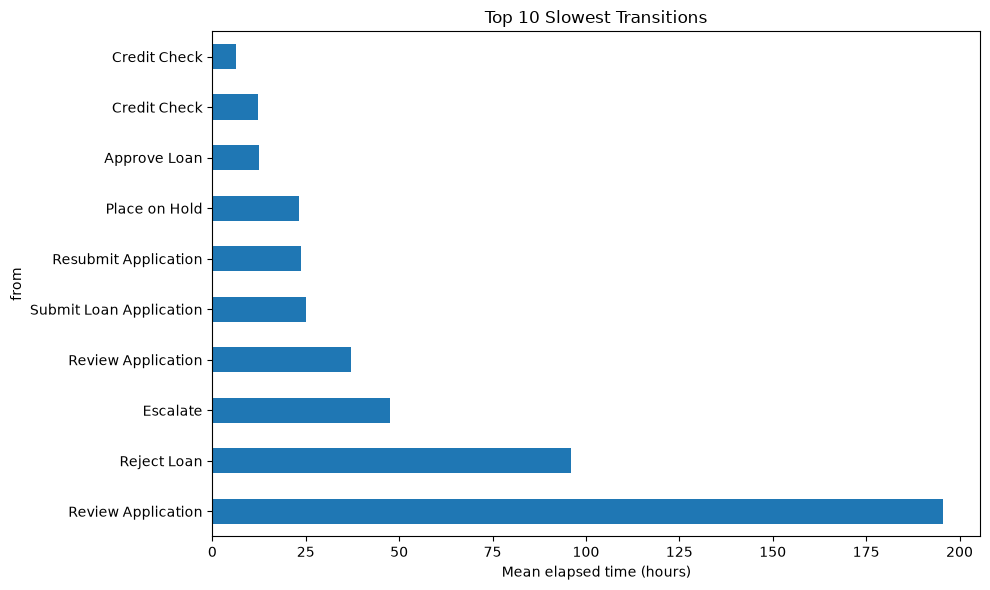

In [20]:
edge_times = [(src, tgt, v['mean']) for (src, tgt), v in perf_dfg.items()]
edge_df = pd.DataFrame(edge_times, columns=["from", "to", "mean_seconds"])
edge_df["mean_hours"] = edge_df["mean_seconds"] / 3600
edge_df = edge_df.sort_values("mean_hours", ascending=False)

print("Top 10 slowest transitions (mean hours):")
print(edge_df.head(10).to_string(index=False))

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
edge_df.head(10).set_index("from")["mean_hours"].plot(kind="barh")
plt.xlabel("Mean elapsed time (hours)")
plt.title("Top 10 Slowest Transitions")
plt.tight_layout()
plt.savefig("/home/barnap86/github_docker/process-mining-pipeline/output/performance.svg", bbox_inches="tight")
plt.show()   